# Plant Disease Classification Using a Custom CNN

**Course:** Computer Vision and Pattern Recognition  
**Student Name:** MD. Saidur Rahman Mahin  
**Student ID:** 23-50578-1  
**Framework:** PyTorch · Google Colab  
**Dataset:** PlantVillage (54,305 color leaf images, 38 classes)

## 1. Import Libraries

This notebook implements a **custom Convolutional Neural Network (CNN)** for identifying plant health conditions using the **PlantVillage** dataset and **PyTorch**.

**Environment:** Google Colab (GPU recommended). This section checks Python/PyTorch, installs packages, imports the required image-processing libraries, mounts Google Drive, and configures private Kaggle authentication.

In [ ]:

# Check Python environment

import sys

print("Python Version:", sys.version)
print("Python is ready!")


Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Python is ready!


In [ ]:

import torch

print("PyTorch Version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Available!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU Not Available. Using CPU.")


PyTorch Version: 2.14.1+cu130
GPU Available!
GPU Name: Tesla T4


In [ ]:

!pip install -q torch torchvision matplotlib numpy pandas scikit-learn seaborn kaggle


In [ ]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [ ]:
import os
import shutil

# Create Kaggle configuration folder
os.makedirs("/root/.kaggle", exist_ok=True)

# Move kaggle.json to the required location
shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")

# Set secure file permission
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle API setup successful!")

## 2. Load and Explore Dataset

**Dataset:** [PlantVillage on Kaggle](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset).


In [ ]:
!kaggle datasets list -s plantvillage

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
# Create a folder for the dataset
import os

os.makedirs("/content/plantvillage", exist_ok=True)

# Download and extract PlantVillage dataset
!kaggle datasets download \
    -d abdallahalidev/plantvillage-dataset \
    -p /content/plantvillage \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset
License(s): CC-BY-NC-SA-4.0
100% 2.04G/2.04G [00:13<00:00, 163MB/s]



In [ ]:
# Check downloaded folders
!ls -lah /content/plantvillage

# Show folder structure
!find /content/plantvillage -maxdepth 3 -type d | head -50

total 12K
drwxr-xr-x 3 root root 4.0K Nov 16 06:59  .
drwxr-xr-x 1 root root 4.0K Nov 16 06:58  ..
drwxr-xr-x 5 root root 4.0K Nov 16 06:59 'plantvillage dataset'
/content/plantvillage
/content/plantvillage/plantvillage dataset
/content/plantvillage/plantvillage dataset/segmented
/content/plantvillage/plantvillage dataset/segmented/Apple___Black_rot
/content/plantvillage/plantvillage dataset/segmented/Peach___Bacterial_spot
/content/plantvillage/plantvillage dataset/segmented/Corn_(maize)___Northern_Leaf_Blight
/content/plantvillage/plantvillage dataset/segmented/Pepper,_bell___Bacterial_spot
/content/plantvillage/plantvillage dataset/segmented/Pepper,_bell___healthy
/content/plantvillage/plantvillage dataset/segmented/Peach___healthy
/content/plantvillage/plantvillage dataset/segmented/Corn_(maize)___Common_rust_
/content/plantvillage/plantvillage dataset/segmented/Tomato___Leaf_Mold
/content/plantvillage/plantvillage dataset/segmented/Blueberry___healthy
/content/plantvillage/plantvi

In [ ]:
import os
from pathlib import Path

# Find the color folder
base_path = Path("/content/plantvillage")

color_folders = list(base_path.rglob("color"))

if color_folders:
    data_dir = color_folders[0]
    print("Dataset folder:", data_dir)

    # Get class folders
    classes = [
        folder for folder in data_dir.iterdir()
        if folder.is_dir()
    ]

    print("Total Classes:", len(classes))

    # Count images in each class
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

    total_images = 0

    for class_folder in sorted(classes):
        image_count = sum(
            1 for file in class_folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in image_extensions
        )

        total_images += image_count

        print(class_folder.name, ":", image_count)

    print("\nTotal Images:", total_images)

else:
    print("Color folder not found. Check the folder structure.")

Dataset folder: /content/plantvillage/plantvillage dataset/color
Total Classes: 38
Apple___Apple_scab : 630
Apple___Black_rot : 621
Apple___Cedar_apple_rust : 275
Apple___healthy : 1645
Blueberry___healthy : 1502
Cherry_(including_sour)___Powdery_mildew : 1052
Cherry_(including_sour)___healthy : 854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513
Corn_(maize)___Common_rust_ : 1192
Corn_(maize)___Northern_Leaf_Blight : 985
Corn_(maize)___healthy : 1162
Grape___Black_rot : 1180
Grape___Esca_(Black_Measles) : 1383
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
Grape___healthy : 423
Orange___Haunglongbing_(Citrus_greening) : 5507
Peach___Bacterial_spot : 2297
Peach___healthy : 360
Pepper,_bell___Bacterial_spot : 997
Pepper,_bell___healthy : 1478
Potato___Early_blight : 1000
Potato___Late_blight : 1000
Potato___healthy : 152
Raspberry___healthy : 371
Soybean___healthy : 5090
Squash___Powdery_mildew : 1835
Strawberry___Leaf_scorch : 1109
Strawberry___healthy : 456
Tomato___Bacter

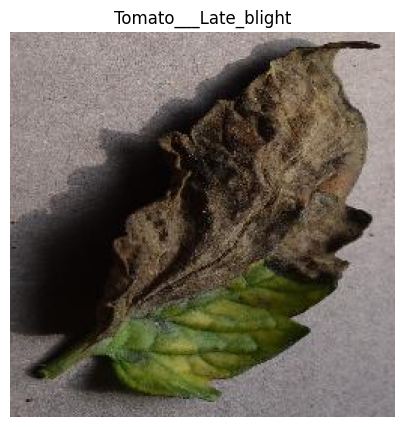

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Select a random class
selected_class = random.choice(classes)

# Select a random image
images = [
    file for file in selected_class.iterdir()
    if file.suffix.lower() in image_extensions
]

random_image = random.choice(images)

# Display image
img = Image.open(random_image)

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(selected_class.name)
plt.axis("off")
plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

# Create a list to store class information
class_data = []

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

for class_folder in sorted(data_dir.iterdir()):
    if class_folder.is_dir():

        image_count = sum(
            1 for file in class_folder.iterdir()
            if file.is_file()
            and file.suffix.lower() in image_extensions
        )

        class_data.append({
            "Class": class_folder.name,
            "Image_Count": image_count
        })

# Create DataFrame
df = pd.DataFrame(class_data)

# Display all classes
print(df.to_string(index=False))

print("\nTotal Classes:", len(df))
print("Total Images:", df["Image_Count"].sum())

                                             Class  Image_Count
                                Apple___Apple_scab          630
                                 Apple___Black_rot          621
                          Apple___Cedar_apple_rust          275
                                   Apple___healthy         1645
                               Blueberry___healthy         1502
          Cherry_(including_sour)___Powdery_mildew         1052
                 Cherry_(including_sour)___healthy          854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot          513
                       Corn_(maize)___Common_rust_         1192
               Corn_(maize)___Northern_Leaf_Blight          985
                            Corn_(maize)___healthy         1162
                                 Grape___Black_rot         1180
                      Grape___Esca_(Black_Measles)         1383
        Grape___Leaf_blight_(Isariopsis_Leaf_Spot)         1076
                                   Grape

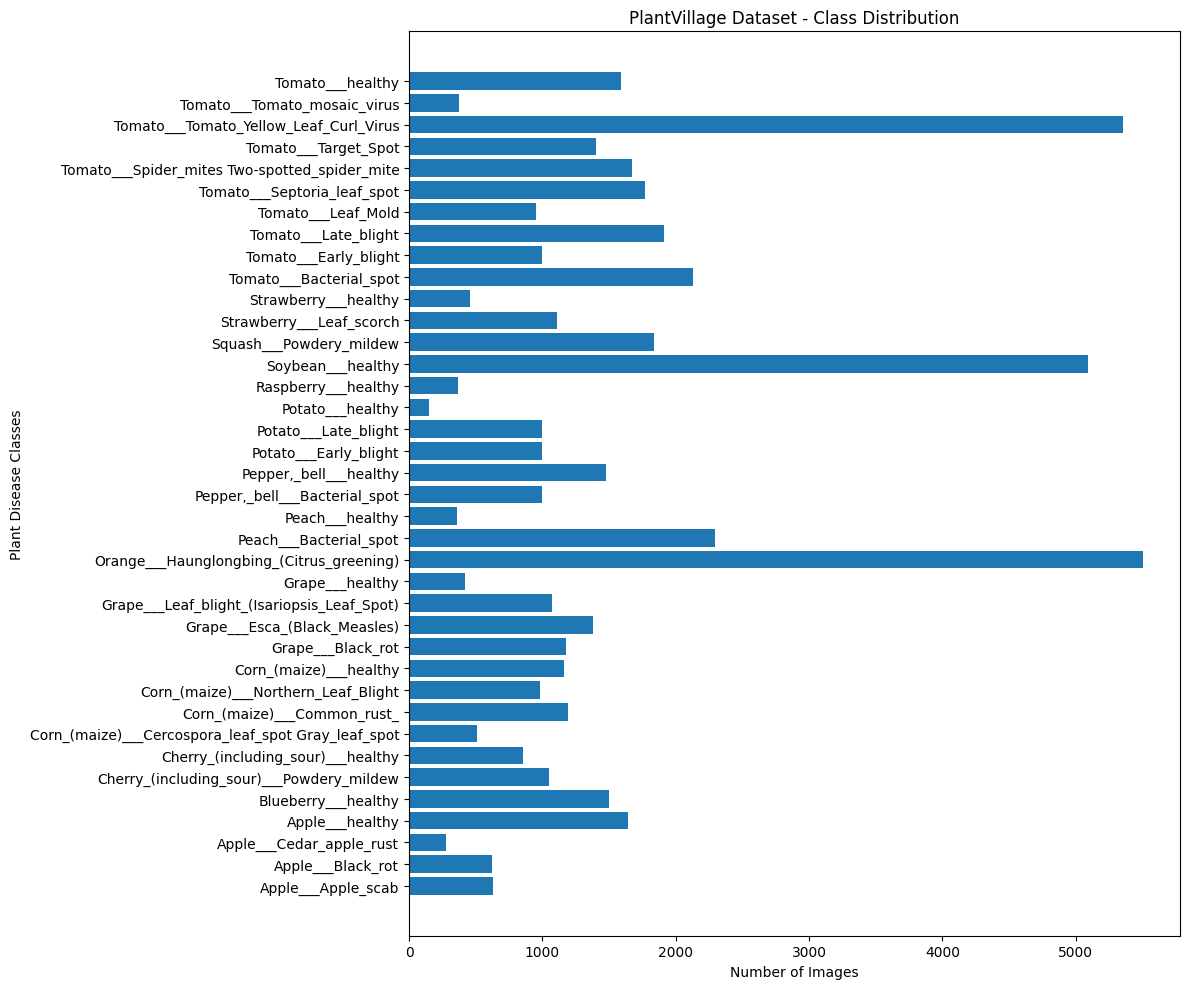

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

plt.barh(
    df["Class"],
    df["Image_Count"]
)

plt.xlabel("Number of Images")
plt.ylabel("Plant Disease Classes")
plt.title("PlantVillage Dataset - Class Distribution")

plt.tight_layout()
plt.show()

In [ ]:
print("Maximum Images in a Class:",
      df["Image_Count"].max())

print("Minimum Images in a Class:",
      df["Image_Count"].min())

print("Average Images per Class:",
      round(df["Image_Count"].mean(), 2))

print("Standard Deviation:",
      round(df["Image_Count"].std(), 2))

Maximum Images in a Class: 5507
Minimum Images in a Class: 152
Average Images per Class: 1429.08
Standard Deviation: 1271.74


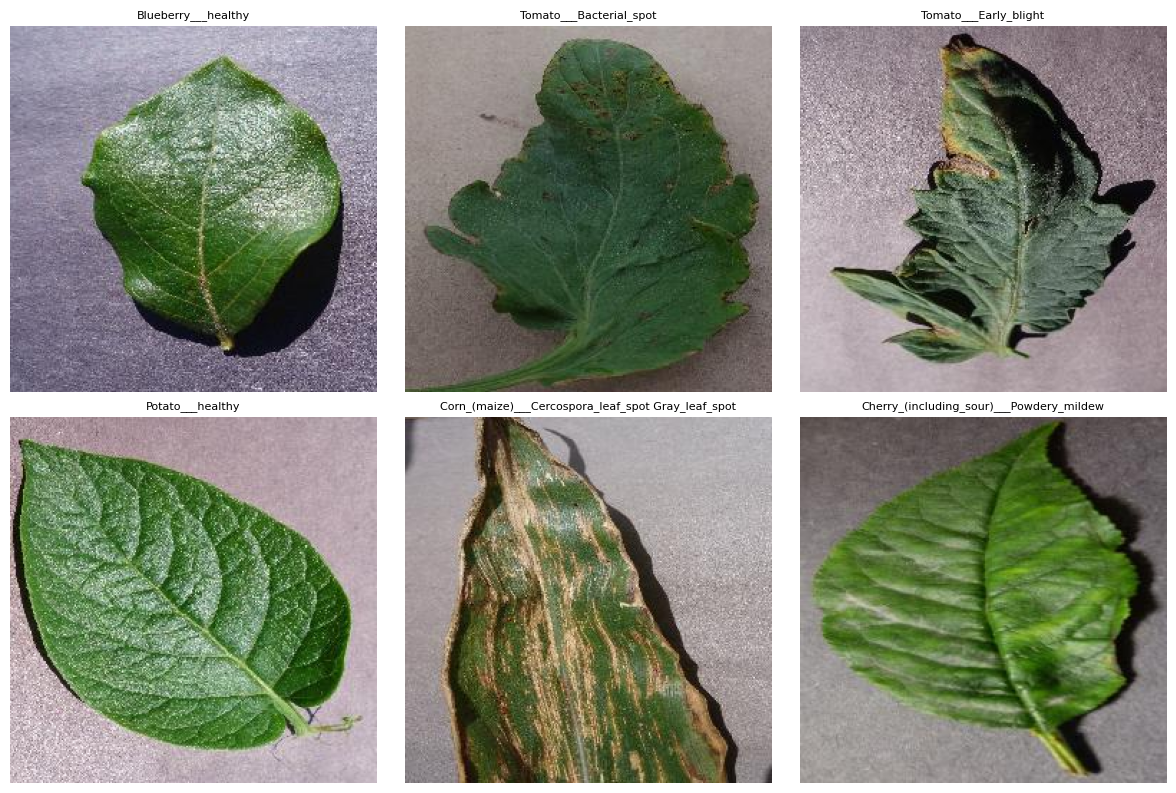

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import random

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax in axes.flat:

    selected_class = random.choice(classes)

    image_files = [
        f for f in selected_class.iterdir()
        if f.suffix.lower() in image_extensions
    ]

    image_path = random.choice(image_files)

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(selected_class.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Augmentation

All images are resized to **128 × 128 RGB** and normalized with the means `[0.485, 0.456, 0.406]` and standard deviations `[0.229, 0.224, 0.225]`.

For **training only**, augmentation applies random horizontal flips and rotations (±15°). Validation and test sets use deterministic resize, tensor conversion, and normalization.

In [ ]:
# Training image transformations
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and Test transformations
eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations created!")

Image transformations created!


In [ ]:
from sklearn.model_selection import train_test_split

# Load dataset without transformations
base_dataset = datasets.ImageFolder(root=str(data_dir))

# Collect labels
labels = np.array(base_dataset.targets)
indices = np.arange(len(base_dataset))

# First split: 70% Train, 30% Temporary
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% Validation, 15% Test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_idx]
)

print("Training Images:", len(train_idx))
print("Validation Images:", len(val_idx))
print("Testing Images:", len(test_idx))
print("Total Images:",
      len(train_idx) + len(val_idx) + len(test_idx))

Training Images: 38013
Validation Images: 8146
Testing Images: 8146
Total Images: 54305


In [ ]:
# Load training dataset with augmentation
train_full = datasets.ImageFolder(
    root=str(data_dir),
    transform=train_transform
)

# Load evaluation dataset without augmentation
eval_full = datasets.ImageFolder(
    root=str(data_dir),
    transform=eval_transform
)

# Create subsets
train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(eval_full, val_idx)
test_dataset = Subset(eval_full, test_idx)

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

Training Dataset: 38013
Validation Dataset: 8146
Testing Dataset: 8146


In [ ]:
# Batch size
batch_size = 32

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")
print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

DataLoaders created successfully!
Training Batches: 1188
Validation Batches: 255
Testing Batches: 255


In [ ]:
# Get one batch of training images
images, labels_batch = next(iter(train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels_batch.shape)
print("Number of Classes:", len(train_full.classes))

Image Batch Shape: torch.Size([32, 3, 128, 128])
Label Batch Shape: torch.Size([32])
Number of Classes: 38


## 4. Define CNN Architecture

The **custom CNN**, implemented from scratch in PyTorch, has three convolutional blocks and a fully connected classifier.

| Layer / operation | Output shape (for 128 × 128 input) |
|---|---|
| Input | 3 × 128 × 128 |
| Conv(3→32, 3×3), ReLU, MaxPool(2×2) | 32 × 64 × 64 |
| Conv(32→64, 3×3), ReLU, MaxPool(2×2) | 64 × 32 × 32 |
| Conv(64→128, 3×3), ReLU, MaxPool(2×2) | 128 × 16 × 16 |
| Flatten → Dense(256), ReLU, Dropout(0.5) | 256 |
| Dense(38) | 38 class logits |

**Total trainable parameters:** 8,491,878. The final layer returns logits; no softmax layer is needed before `CrossEntropyLoss`.

In [ ]:
import torch
import torch.nn as nn

# Define Custom CNN Model
class PlantDiseaseCNN(nn.Module):

    def __init__(self, num_classes=38):
        super(PlantDiseaseCNN, self).__init__()

        # Convolutional Block 1
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolutional Block 2
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Convolutional Block 3
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        # Fully Connected Layers
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 16 * 16, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)

        x = self.fc(x)

        return x


print("Custom CNN Architecture Created!")

Custom CNN Architecture Created!


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)

Using Device: cuda


In [ ]:
model = PlantDiseaseCNN(num_classes=38)

model = model.to(device)

print(model)

PlantDiseaseCNN(
  (conv1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=38, bias=True)
  )
)


In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

Total Parameters: 8491878
Trainable Parameters: 8491878


In [ ]:
# Create a dummy batch
dummy_input = torch.randn(1, 3, 128, 128).to(device)

# Test model
model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input Shape:", dummy_input.shape)
print("Output Shape:", output.shape)

Input Shape: torch.Size([1, 3, 128, 128])
Output Shape: torch.Size([1, 38])


## 5. Training Loop with Validation

**Training configuration:** `CrossEntropyLoss`, Adam optimizer, learning rate **0.001**, batch size **32**, and **5 epochs**. Each epoch calculates training and validation loss/accuracy; the weights with the highest validation accuracy are saved to `/content/best_plant_disease_cnn.pth`.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Loss Function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        # Move images and labels to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward Pass
        outputs = model(images)

        # Calculate Loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Calculate statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


print("Training and Validation functions created!")

Training and Validation functions created!


In [ ]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

print("Training history initialized!")

Training history initialized!


In [ ]:
import time

num_epochs = 5

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    start_time = time.time()

    # Training
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # Validation
    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    # Save history
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # Save best model
    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            model.state_dict(),
            "/content/best_plant_disease_cnn.pth"
        )

    epoch_time = time.time() - start_time

    print(f"Epoch [{epoch+1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.2f}%")
    print(f"Time: {epoch_time:.2f} seconds")
    print("-" * 50)

print("Training Completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.2f}%")

Epoch [1/5]
Train Loss: 1.2944 | Train Accuracy: 62.70%
Val Loss: 0.5050 | Val Accuracy: 83.81%
Time: 88.71 seconds
--------------------------------------------------
Epoch [2/5]
Train Loss: 0.6466 | Train Accuracy: 80.04%
Val Loss: 0.3390 | Val Accuracy: 89.01%
Time: 87.43 seconds
--------------------------------------------------
Epoch [3/5]
Train Loss: 0.4657 | Train Accuracy: 85.51%
Val Loss: 0.2476 | Val Accuracy: 92.29%
Time: 88.18 seconds
--------------------------------------------------
Epoch [4/5]
Train Loss: 0.3779 | Train Accuracy: 87.94%
Val Loss: 0.1939 | Val Accuracy: 93.79%
Time: 87.60 seconds
--------------------------------------------------
Epoch [5/5]
Train Loss: 0.3258 | Train Accuracy: 89.83%
Val Loss: 0.1647 | Val Accuracy: 94.24%
Time: 88.14 seconds
--------------------------------------------------
Training Completed!
Best Validation Accuracy: 94.24%


In [ ]:
import os

model_path = "/content/best_plant_disease_cnn.pth"

if os.path.exists(model_path):
    print("Best Model Saved Successfully!")
    print("File Size:",
          round(os.path.getsize(model_path) / (1024 * 1024), 2),
          "MB")
else:
    print("Model file not found!")

Best Model Saved Successfully!
File Size: 32.4 MB


In [ ]:
from google.colab import files

files.download("/content/best_plant_disease_cnn.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Evaluate Model on Test Set

The best saved checkpoint is loaded before test inference. Predictions are gathered with `model.eval()` and `torch.no_grad()`; the classification report and macro-averaged metrics are calculated on the held-out test set.

In [ ]:
import torch
import os

model_path = "/content/best_plant_disease_cnn.pth"

# Check whether the saved model exists
if not os.path.exists(model_path):
    raise FileNotFoundError(
        "Model file not found! Check your saved model path."
    )

# Load the best trained weights
model.load_state_dict(
    torch.load(
        model_path,
        map_location=device,
        weights_only=True
    )
)

# Move model to GPU or CPU
model = model.to(device)

# Set evaluation mode
model.eval()

print("Best CNN Model Loaded Successfully!")

Best CNN Model Loaded Successfully!


In [ ]:
import numpy as np

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        # Move images to GPU
        images = images.to(device)

        # Forward pass
        outputs = model(images)

        # Get predicted class
        _, predicted = torch.max(outputs, 1)

        # Store results
        all_predictions.extend(
            predicted.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

# Convert lists to NumPy arrays
all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Total Test Images:", len(all_labels))
print("Total Predictions:", len(all_predictions))

Total Test Images: 8146
Total Predictions: 8146


In [ ]:
from sklearn.metrics import accuracy_score

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Accuracy: 95.00%


In [ ]:
from sklearn.metrics import classification_report

# Get class names
class_names = train_full.classes

# Generate classification report
report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("Classification Report:")
print(report)

Classification Report:
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.8791    0.8511    0.8649        94
                                 Apple___Black_rot     0.9787    0.9892    0.9840        93
                          Apple___Cedar_apple_rust     0.9500    0.9268    0.9383        41
                                   Apple___healthy     0.9598    0.8740    0.9149       246
                               Blueberry___healthy     0.9489    0.9867    0.9675       226
          Cherry_(including_sour)___Powdery_mildew     0.9811    0.9873    0.9842       158
                 Cherry_(including_sour)___healthy     0.9398    0.9766    0.9579       128
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8919    0.4286    0.5789        77
                       Corn_(maize)___Common_rust_     0.9834    0.9944    0.9889       179
               Corn_(maize)___Northern_Leaf_Blight     0

In [ ]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall: {recall * 100:.2f}%")
print(f"Macro F1-score: {f1 * 100:.2f}%")

Test Accuracy: 95.00%
Macro Precision: 94.15%
Macro Recall: 92.41%
Macro F1-score: 92.80%


In [ ]:
import pandas as pd

report_dict = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    "/content/classification_report.csv"
)

print("Classification Report CSV Saved!")

Classification Report CSV Saved!


## 7. Visualizations (Loss/Accuracy Curves)

This section contains the original training/validation loss and accuracy plots and the **38-class confusion matrix**. It also saves the confusion matrix to `/content/confusion_matrix.png` and exports plot images into `/content/PlantDiseaseCNN_Final/`.

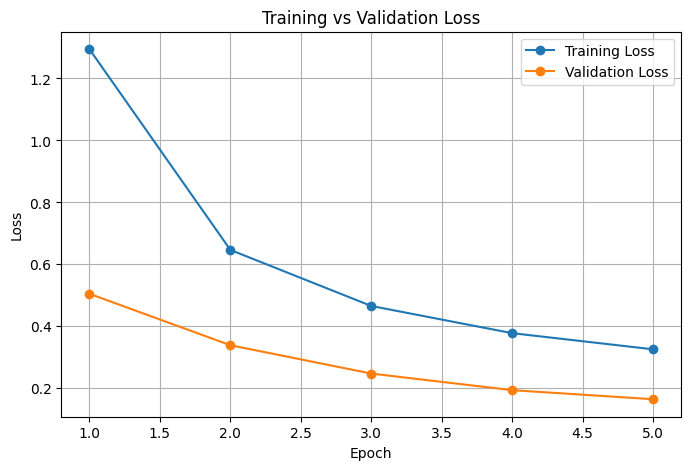

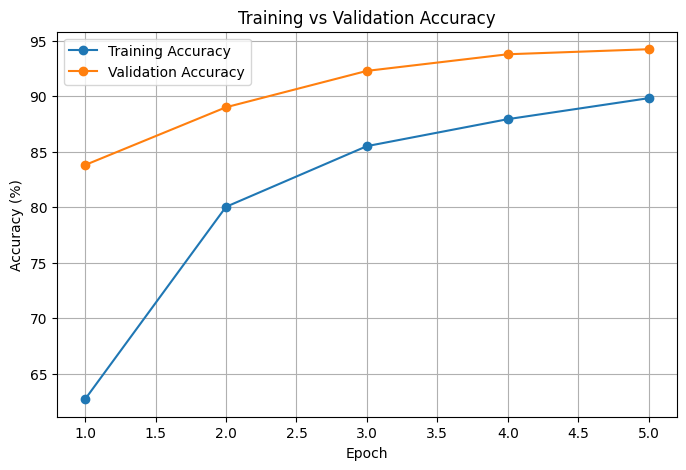

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Loss Graph
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# Accuracy Graph
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

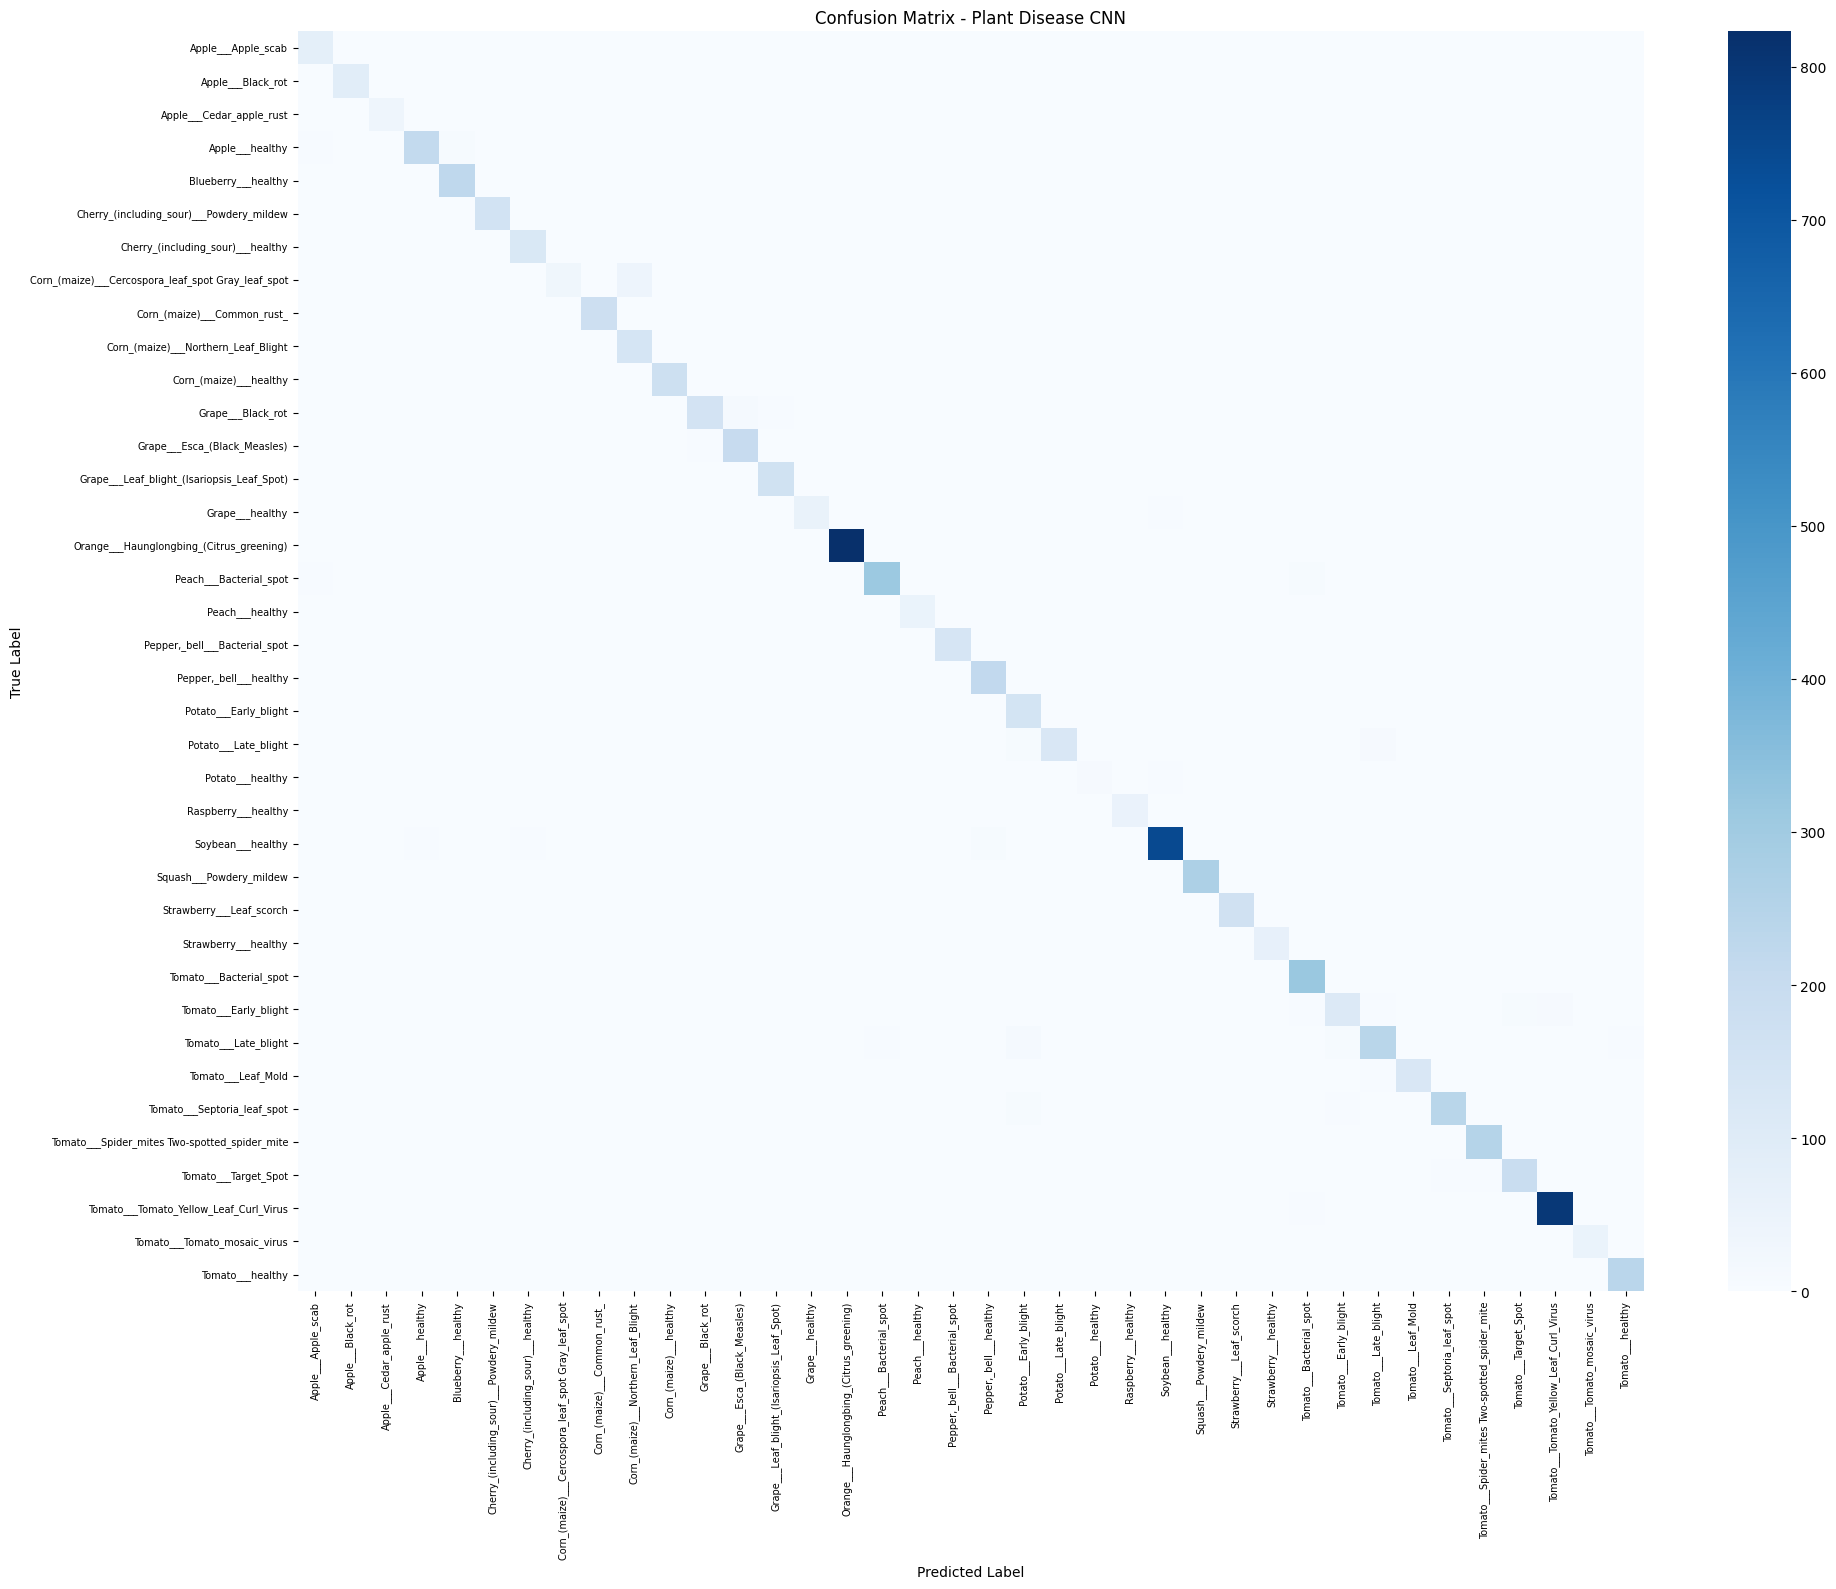

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Plant Disease CNN")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()
plt.show()

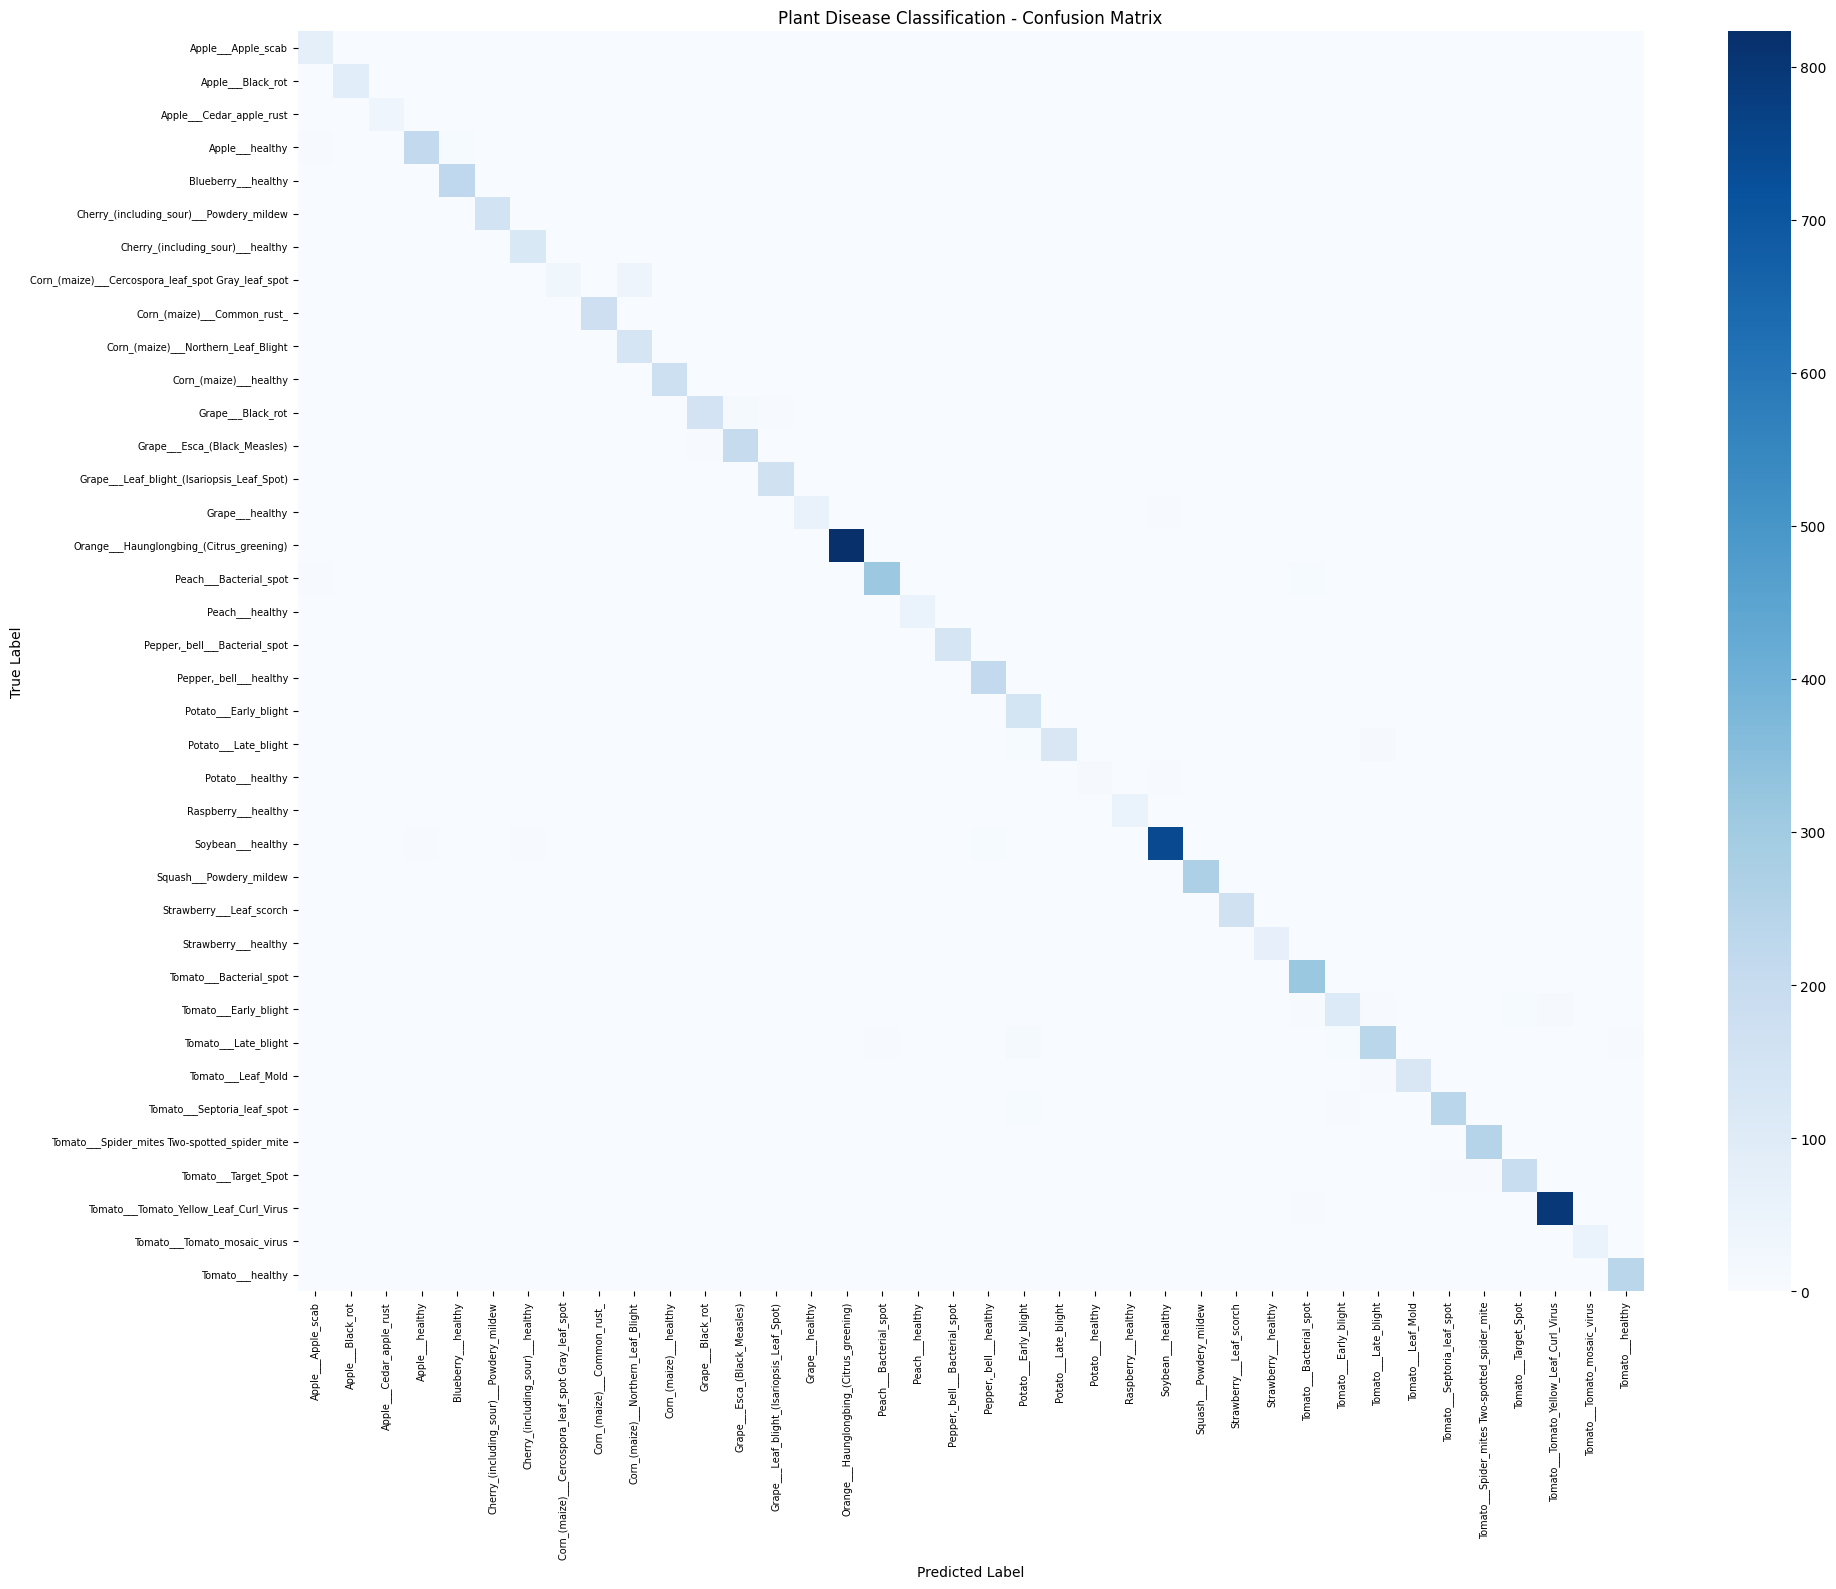

Confusion Matrix Saved Successfully!


In [ ]:
plt.figure(figsize=(20, 16))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Plant Disease Classification - Confusion Matrix")

plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion Matrix Saved Successfully!")

In [ ]:
import os
import shutil

project_folder = "/content/PlantDiseaseCNN_Final"

os.makedirs(project_folder, exist_ok=True)

files_to_copy = [
    "/content/best_plant_disease_cnn.pth",
    "/content/confusion_matrix.png",
    "/content/classification_report.csv"
]

for file_path in files_to_copy:
    if os.path.exists(file_path):
        shutil.copy2(file_path, project_folder)
        print("Copied:", os.path.basename(file_path))
    else:
        print("Missing:", file_path)

print("Project folder prepared!")

Copied: best_plant_disease_cnn.pth
Copied: confusion_matrix.png
Copied: classification_report.csv
Project folder prepared!


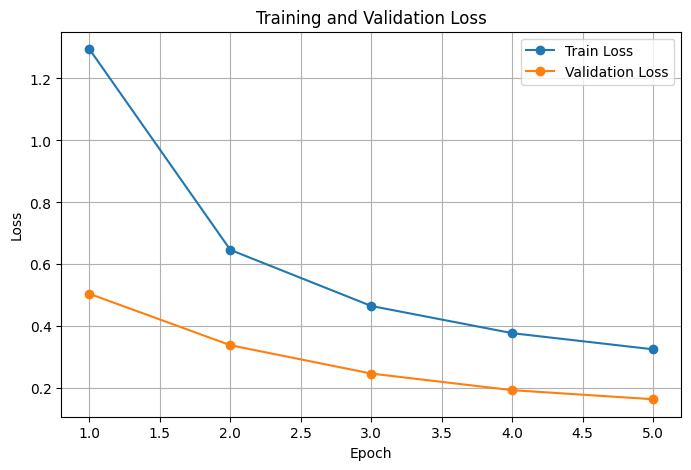

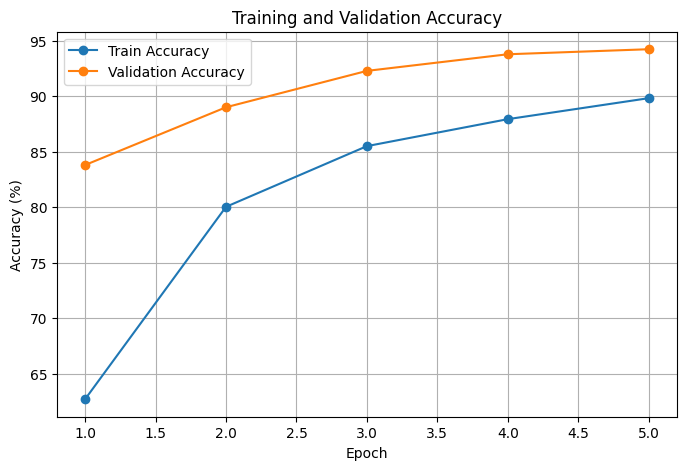

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

# Training and Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{project_folder}/loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Training and Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracies, marker="o", label="Train Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    f"{project_folder}/accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from google.colab import drive
import shutil

drive.mount("/content/drive")

destination = "/content/drive/MyDrive/PlantDiseaseCNN_Final"

shutil.copytree(
    project_folder,
    destination,
    dirs_exist_ok=True
)

print("Final project files backed up to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Final project files backed up to Google Drive!


## 8. Analysis & Discussion of Results

### Class-wise findings

The best class-level F1-scores in the recorded test evaluation include:

| Class | F1-score |
|---|---:|
| Strawberry healthy | 99.27% |
| Squash Powdery Mildew | 99.27% |
| Orange Huanglongbing | 99.16% |
| Corn healthy | 99.15% |
| Corn Common Rust | 98.89% |

The most difficult class was **Corn (maize) Cercospora / Gray Leaf Spot**, with an **F1-score of 57.89%** and **recall of 42.86%** (77 test samples). **Potato healthy** also had lower recall (**52.17%**, 23 test samples).

### Confusion patterns

The most frequent directional error was **Corn Gray Leaf Spot → Corn Northern Leaf Blight** (**43** images). Other notable errors were **Grape Black Rot → Grape Esca** (**16**) and **Tomato Late Blight → Potato Early Blight** (**14**).

These results show that a high overall accuracy can coexist with substantial errors for individual classes. Similar visible symptoms may contribute to confusion, but the images would need to be reviewed to establish why the errors occur.

In [ ]:
# Get class-wise performance
class_results = report_df.loc[class_names].copy()

# Best 5 classes based on F1-score
best_classes = class_results.sort_values(
    by="f1-score",
    ascending=False
).head(5)

# Worst 5 classes based on F1-score
worst_classes = class_results.sort_values(
    by="f1-score",
    ascending=True
).head(5)

print("Top 5 Best Performing Classes:")
print(best_classes)

print("\nTop 5 Worst Performing Classes:")
print(worst_classes)

Top 5 Best Performing Classes:
                                          precision    recall  f1-score  \
Strawberry___healthy                       0.985507  1.000000  0.992701   
Squash___Powdery_mildew                    1.000000  0.985455  0.992674   
Orange___Haunglongbing_(Citrus_greening)   0.986811  0.996368  0.991566   
Corn_(maize)___healthy                     0.983051  1.000000  0.991453   
Corn_(maize)___Common_rust_                0.983425  0.994413  0.988889   

                                          support  
Strawberry___healthy                         68.0  
Squash___Powdery_mildew                     275.0  
Orange___Haunglongbing_(Citrus_greening)    826.0  
Corn_(maize)___healthy                      174.0  
Corn_(maize)___Common_rust_                 179.0  

Top 5 Worst Performing Classes:
                                                    precision    recall  \
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   0.891892  0.428571   
Potato___healthy       

In [ ]:
import numpy as np

# Copy confusion matrix
cm_errors = cm.copy()

# Remove correct predictions (diagonal)
np.fill_diagonal(cm_errors, 0)

# Find the largest off-diagonal errors
error_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm_errors[i, j] > 0:
            error_pairs.append((
                class_names[i],
                class_names[j],
                int(cm_errors[i, j])
            ))

error_pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 5 Most Confused Class Pairs:")

for actual, predicted, count in error_pairs[:5]:
    print(
        f"Actual: {actual} | "
        f"Predicted: {predicted} | "
        f"Errors: {count}"
    )

Top 5 Most Confused Class Pairs:
Actual: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Predicted: Corn_(maize)___Northern_Leaf_Blight | Errors: 43
Actual: Grape___Black_rot | Predicted: Grape___Esca_(Black_Measles) | Errors: 16
Actual: Tomato___Late_blight | Predicted: Potato___Early_blight | Errors: 14
Actual: Potato___Late_blight | Predicted: Tomato___Late_blight | Errors: 11
Actual: Tomato___Early_blight | Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus | Errors: 10


In [ ]:
# Get class-wise performance
class_results = report_df.loc[class_names].copy()

# Best 5 classes
best_classes = class_results.sort_values(
    by="f1-score",
    ascending=False
).head(5)

# Worst 5 classes
worst_classes = class_results.sort_values(
    by="f1-score",
    ascending=True
).head(5)

print("Top 5 Best Performing Classes:")
print(best_classes)

print("\nTop 5 Worst Performing Classes:")
print(worst_classes)

Top 5 Best Performing Classes:
                                          precision    recall  f1-score  \
Strawberry___healthy                       0.985507  1.000000  0.992701   
Squash___Powdery_mildew                    1.000000  0.985455  0.992674   
Orange___Haunglongbing_(Citrus_greening)   0.986811  0.996368  0.991566   
Corn_(maize)___healthy                     0.983051  1.000000  0.991453   
Corn_(maize)___Common_rust_                0.983425  0.994413  0.988889   

                                          support  
Strawberry___healthy                         68.0  
Squash___Powdery_mildew                     275.0  
Orange___Haunglongbing_(Citrus_greening)    826.0  
Corn_(maize)___healthy                      174.0  
Corn_(maize)___Common_rust_                 179.0  

Top 5 Worst Performing Classes:
                                                    precision    recall  \
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot   0.891892  0.428571   
Potato___healthy       

In [ ]:
import numpy as np

cm_errors = cm.copy()

# Remove correct predictions
np.fill_diagonal(cm_errors, 0)

error_pairs = []

for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm_errors[i, j] > 0:
            error_pairs.append((
                class_names[i],
                class_names[j],
                int(cm_errors[i, j])
            ))

error_pairs.sort(
    key=lambda x: x[2],
    reverse=True
)

print("Top 5 Most Confused Class Pairs:")

for actual, predicted, count in error_pairs[:5]:
    print(
        f"Actual: {actual} | "
        f"Predicted: {predicted} | "
        f"Errors: {count}"
    )

Top 5 Most Confused Class Pairs:
Actual: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot | Predicted: Corn_(maize)___Northern_Leaf_Blight | Errors: 43
Actual: Grape___Black_rot | Predicted: Grape___Esca_(Black_Measles) | Errors: 16
Actual: Tomato___Late_blight | Predicted: Potato___Early_blight | Errors: 14
Actual: Potato___Late_blight | Predicted: Tomato___Late_blight | Errors: 11
Actual: Tomato___Early_blight | Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus | Errors: 10


## 9. Conclusions & Future Work

### Conclusion

A custom PyTorch CNN was developed for **38-way PlantVillage image classification** using **54,305** color images. On the held-out test subset, the recorded model achieved **95.00% accuracy**, **94.15% macro precision**, **92.41% macro recall**, and **92.80% macro F1-score**. The best validation accuracy was **94.24%** after five epochs.

The results demonstrate strong performance on the supplied dataset, but errors remain concentrated in certain disease classes, particularly **Corn Gray Leaf Spot**. The gap between test accuracy and macro recall reinforces the importance of class-wise evaluation.

### Limitations

- **Class imbalance:** The number of examples per class varies considerably.
- **Underperforming classes:** Gray Leaf Spot and Potato healthy show notably lower recall.
- **Generalization:** PlantVillage color images do not fully represent real field conditions (lighting, backgrounds, occlusion, and camera variation).
- **Potential data leakage:** The image-level random split may put closely related images in different subsets; this was not checked at plant/leaf level.
- **Computational cost:** The network has about 8.49 million trainable parameters and was trained for only five epochs.

### Future Work

- Analyze misclassified leaf images and class-specific confusion patterns.
- Experiment with class-balanced sampling or class-weighted loss.
- Tune augmentation, regularization, learning rate, and training duration.
- Compare with smaller CNN architectures or transfer-learning baselines.
- Evaluate on an **independent real-world field dataset** and, where possible, a split grouped by source plant/leaf.